INVENTORY DATA SAMPLE
product_id  daily_demand  current_stock  lead_time_days  unit_cost  lead_time_demand  safety_stock  reorder_point  days_of_stock  inventory_value inventory_status  target_stock  suggested_order_qty  estimated_order_cost
      P001            43            411               9     138.45               387            78            465            9.6         56902.95     Reorder Soon          1368                  957             132496.65
      P002            33            182              12     902.35               396            80            476            5.5        164227.70    Stockout Risk          1070                  888             801286.80
      P003            19            438              10     905.40               190            38            228           23.1        396565.20 Sufficient Stock           608                  170             153918.00
      P004            47            308               6     651.45               282            57

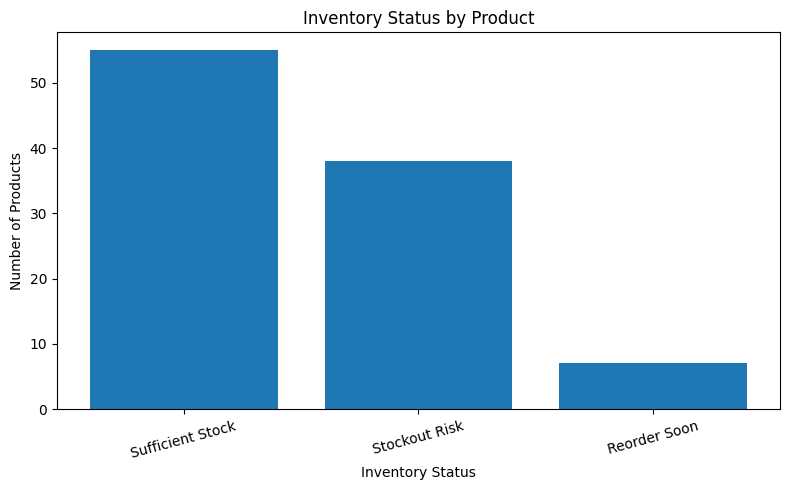

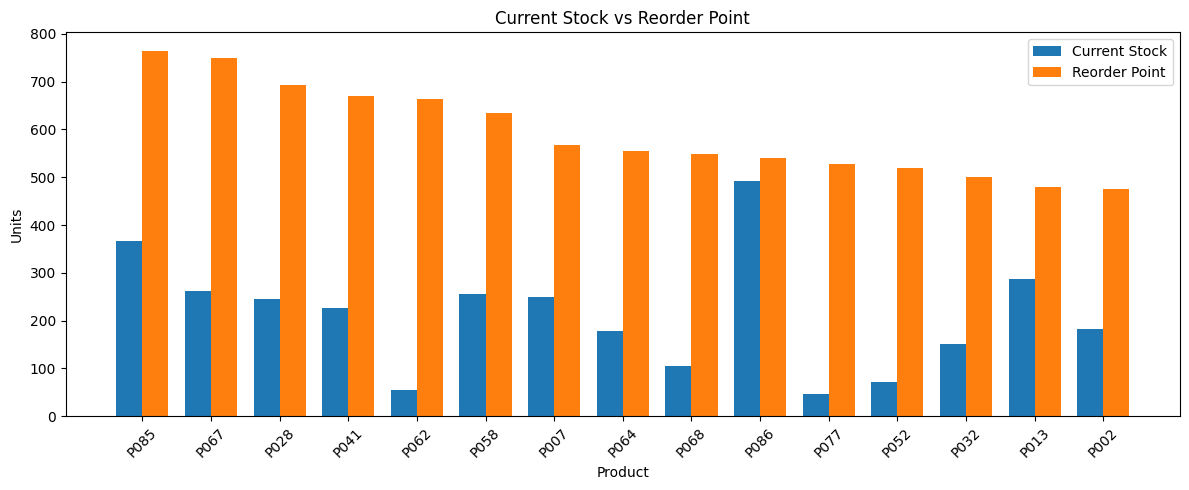


PRODUCTS REQUIRING ATTENTION
product_id  daily_demand  current_stock  lead_time_days  reorder_point inventory_status  suggested_order_qty  estimated_order_cost
      P004            47            308               6            339     Reorder Soon                 1159             755030.55
      P022            42            191               4            202     Reorder Soon                 1103             780151.90
      P001            43            411               9            465     Reorder Soon                  957             132496.65
      P086            45            492              10            540     Reorder Soon                  948             499065.12
      P021            34            118               3            123     Reorder Soon                  923             527309.90
      P073            19             81               4             92     Reorder Soon                  505              92455.40
      P075            18            153              

In [1]:

# PROJECT 10: INVENTORY OPTIMIZATION

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

np.random.seed(42)

# 1. Create a sample inventory dataset
n = 100

df = pd.DataFrame({
    "product_id": [f"P{i:03d}" for i in range(1, n + 1)],
    "daily_demand": np.random.randint(5, 50, n),
    "current_stock": np.random.randint(20, 500, n),
    "lead_time_days": np.random.randint(2, 15, n),
    "unit_cost": np.random.uniform(50, 1000, n).round(2)
})

# 2. Estimate demand during supplier lead time
df["lead_time_demand"] = (
    df["daily_demand"] * df["lead_time_days"]
)

# Safety stock: 20% of estimated lead-time demand
df["safety_stock"] = np.ceil(
    df["lead_time_demand"] * 0.20
).astype(int)

# Reorder point = lead-time demand + safety stock
df["reorder_point"] = (
    df["lead_time_demand"] + df["safety_stock"]
)

# 3. Calculate stock coverage and inventory value
df["days_of_stock"] = (
    df["current_stock"] / df["daily_demand"]
).round(1)

df["inventory_value"] = (
    df["current_stock"] * df["unit_cost"]
).round(2)

# 4. Identify inventory status
def inventory_status(row):
    if row["current_stock"] < row["lead_time_demand"]:
        return "Stockout Risk"
    elif row["current_stock"] <= row["reorder_point"]:
        return "Reorder Soon"
    else:
        return "Sufficient Stock"

df["inventory_status"] = df.apply(
    inventory_status, axis=1
)

# 5. Calculate suggested replenishment quantity
# Target stock = 30 days of estimated demand + safety stock
df["target_stock"] = (
    df["daily_demand"] * 30 + df["safety_stock"]
)

df["suggested_order_qty"] = (
    df["target_stock"] - df["current_stock"]
).clip(lower=0).astype(int)

df["estimated_order_cost"] = (
    df["suggested_order_qty"] * df["unit_cost"]
).round(2)

# 6. Display sample results
print("INVENTORY DATA SAMPLE")
print(df.head(10).to_string(index=False))

# 7. Summarize inventory status
print("\nINVENTORY STATUS SUMMARY")
print(df["inventory_status"].value_counts())

# 8. Overall inventory metrics
total_inventory_value = df["inventory_value"].sum()
total_recommended_cost = df["estimated_order_cost"].sum()
stockout_risk_count = (
    df["inventory_status"] == "Stockout Risk"
).sum()
reorder_soon_count = (
    df["inventory_status"] == "Reorder Soon"
).sum()

print("\nKEY INVENTORY METRICS")
print("Number of products:", len(df))
print("Total inventory value: ₹", round(total_inventory_value, 2))
print("Products at stockout risk:", stockout_risk_count)
print("Products to reorder soon:", reorder_soon_count)
print(
    "Estimated cost of suggested orders: ₹",
    round(total_recommended_cost, 2)
)

# 9. Plot inventory status
status_counts = df["inventory_status"].value_counts()

plt.figure(figsize=(8, 5))
plt.bar(status_counts.index, status_counts.values)
plt.title("Inventory Status by Product")
plt.xlabel("Inventory Status")
plt.ylabel("Number of Products")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

# 10. Compare current stock and reorder points
sample = df.sort_values(
    "reorder_point", ascending=False
).head(15)

x = np.arange(len(sample))
width = 0.38

plt.figure(figsize=(12, 5))
plt.bar(
    x - width / 2,
    sample["current_stock"],
    width,
    label="Current Stock"
)
plt.bar(
    x + width / 2,
    sample["reorder_point"],
    width,
    label="Reorder Point"
)
plt.xticks(x, sample["product_id"], rotation=45)
plt.title("Current Stock vs Reorder Point")
plt.xlabel("Product")
plt.ylabel("Units")
plt.legend()
plt.tight_layout()
plt.show()

# 11. Identify products requiring attention
priority_products = df[
    df["inventory_status"] != "Sufficient Stock"
].sort_values(
    ["inventory_status", "suggested_order_qty"],
    ascending=[True, False]
)

print("\nPRODUCTS REQUIRING ATTENTION")
print(
    priority_products[
        [
            "product_id",
            "daily_demand",
            "current_stock",
            "lead_time_days",
            "reorder_point",
            "inventory_status",
            "suggested_order_qty",
            "estimated_order_cost"
        ]
    ].head(20).to_string(index=False)
)

# 12. Business recommendations
print("\nBUSINESS RECOMMENDATIONS")
print("1. Prioritize products with stockout risk.")
print("2. Reorder products when stock reaches the reorder point.")
print("3. Review supplier lead times regularly.")
print("4. Monitor slow-moving and high-value inventory.")
print("5. Validate demand estimates before placing actual orders.")

print("\nDISCLAIMER")
print("This project uses synthetic data and illustrative assumptions.")
print("Suggested order quantities are planning estimates, not actual purchase orders.")
